# 📱 Impacto das Redes Sociais na Saúde e no Desempenho de Estudantes
### Relatório de Análise — Correlações
*Big Data e Processamento Otimizado com Python II*

| | |
|---|---|
| **Autora** | Indiara, Dialuan e Guilherme
| **Base de dados** | `estudantes.parquet` — 500.000 estudantes, 48 variáveis |
| **Ferramentas** | Python, Polars, Matplotlib e Seaborn |
| **Continuação de** | Parte 1 (faixas de uso e sono) e Parte 2 (distribuição do uso de redes) |
| **Esta etapa** | Correlações de Pearson e Spearman no nível do estudante |

**Pergunta de pesquisa:** o uso de redes sociais está associado à **saúde** (sono e bem-estar) e ao **desempenho** (frequência, atenção e risco acadêmico)?

---

## 🧭 Sumário

1. [Resumo executivo](#1-resumo-executivo)
2. [Introdução e conexão com as etapas anteriores](#2-introdução-e-conexão-com-as-etapas-anteriores)
3. [Dados e metodologia](#3-dados-e-metodologia)
4. [Resultados](#4-resultados)
   - 4.1 [Matriz de correlação](#41-matriz-de-correlação)
   - 4.2 [Preditores × saúde e desempenho](#42-preditores--saúde-e-desempenho)
   - 4.3 [Dispersão dos pares mais fortes](#43-dispersão-dos-pares-mais-fortes)
   - 4.4 [Médias por nível de uso de redes](#44-médias-por-nível-de-uso-de-redes)
   - 4.5 [Síntese das associações](#45-síntese-das-associações)
5. [Discussão](#5-discussão)
6. [Conclusões e limitações](#6-conclusões-e-limitações)
7. [Próximos passos](#7-próximos-passos)

---

## 1. Resumo executivo

| Pergunta | Resultado |
|---|---|
| 😴 Redes sociais × sono | **r = -0,76** (forte e negativa): quanto mais redes, menos sono |
| 💚 Redes sociais × bem-estar | **r = -0,63** (forte e negativa) |
| 🎯 Redes sociais × atenção | **r = -0,43** (moderada e negativa) |
| 🏫 Redes sociais × frequência às aulas | **r = -0,28** (fraca e negativa) |
| 📉 Redes sociais × risco acadêmico | **r = +0,18** (fraca e positiva) |
| 🔁 Pearson × Spearman | **resultados muito próximos** em todos os pares, o que indica relações lineares e estáveis |

> 💡 **Mensagem central:** a associação com o uso de redes é **forte para a saúde** (sono e bem-estar), **moderada para a atenção** e **fraca para a frequência e o risco acadêmico**. O padrão sugere que o impacto das redes aparece primeiro na saúde e chega ao desempenho de forma mais atenuada.

---

## 2. Introdução e conexão com as etapas anteriores

| Etapa | O que mostrou |
|---|---|
| **Parte 1** | Bem-estar médio de **74,11** (pouco uso e sono bom) contra **45,15** (alto uso e sono baixo), e 97,8% dos usuários intensos dormem 6 h ou menos |
| **Parte 2** | Uso médio de **3,36 h/dia**, distribuição simétrica, e faixa *Alto* (≥ 5 h) com cerca de 11% dos estudantes |
| **Esta etapa** | **Quantifica** essas relações com coeficientes de correlação e inclui o **desempenho** (frequência, atenção e risco acadêmico) |

As etapas anteriores mostraram **diferenças entre grupos**. Aqui, o objetivo é medir a **força e a direção** da associação entre as variáveis, usando todos os 500.000 estudantes, sem agrupamento.

---

## 3. Dados e metodologia

### 3.1 Variáveis do estudo

| Papel | Variável | Descrição |
|---|---|---|
| **Preditor** | `horas_redes_sociais` | Horas diárias em redes sociais |
| **Preditor** | `pontuacao_vicio_digital` | Pontuação de vício digital |
| **Saúde** | `horas_sono` | Horas diárias de sono |
| **Saúde** | `indice_bem_estar` | Índice de bem-estar |
| **Desempenho** | `taxa_frequencia_aulas` | Frequência às aulas |
| **Desempenho** | `capacidade_atencao_minutos` | Capacidade de atenção, em minutos |
| **Desempenho** | `pontuacao_risco_academico` | Risco acadêmico (quanto maior, pior) |

### 3.2 Coeficientes e escala de interpretação

- **Pearson:** mede a relação **linear** entre duas variáveis.
- **Spearman:** mede a relação **monotônica** (por ordem) e é robusto a valores extremos.
- **r²:** parte da variação de uma variável que a outra explica linearmente.

| \|r\| | Classificação |
|---|---|
| Abaixo de 0,10 | Desprezível |
| De 0,10 a 0,30 | Fraca |
| De 0,30 a 0,50 | Moderada |
| 0,50 ou mais | Forte |

### 3.3 Preparação dos dados
Define as funções de apoio (resumos por grupo e categorias de sono e de redes, as mesmas da Parte 1) e identifica as colunas da base.

In [1]:
import time
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ARQUIVO = "estudantes.parquet"

inicial = pl.scan_parquet(ARQUIVO)
esquema = inicial.collect_schema()
colunas = esquema.names()
numericas = [c for c, t in esquema.items() if t.is_numeric()]

# Métricas de saúde e desempenho usadas nos resumos
METRICAS = list(dict.fromkeys(
    c for c in ["horas_redes_sociais", "horas_sono", "pontuacao_vicio_digital", "indice_bem_estar",
                "taxa_frequencia_aulas", "capacidade_atencao_minutos", "pontuacao_risco_academico",]
    if c and c in colunas
))

def perfil(lf, grupo):
    """Resumo por grupo: nº de estudantes + média das métricas do tema."""
    return (
        lf.group_by(grupo)
        .agg([pl.len().alias("estudantes")] +
             [pl.col(c).mean().round(2).alias(f"media_{c}") for c in METRICAS])
        .sort(grupo)
    )


def categorizar(lf):
    """Cria categorias de sono, redes sociais."""
    exprs = [
        pl.when(pl.col("horas_sono") <= 6).then(pl.lit("1-Baixo (≤6h)"))
          .when(pl.col("horas_sono") < 8).then(pl.lit("2-Médio (6-8h)"))
          .otherwise(pl.lit("3-Bom (≥8h)")).alias("categoria_sono"),
        pl.when(pl.col("horas_redes_sociais") < 2).then(pl.lit("1-Baixo (<2h)"))
          .when(pl.col("horas_redes_sociais") < 5).then(pl.lit("2-Moderado (2-5h)"))
          .otherwise(pl.lit("3-Alto (≥5h)")).alias("categoria_redes"),
    ]
    return lf.with_columns(exprs)

### 3.4 Seleção das variáveis
Separa preditores, indicadores de saúde e de desempenho, e remove registros com valores ausentes.

In [2]:
preditores = [c for c in ["horas_redes_sociais", "pontuacao_vicio_digital"] if c and c in colunas]
saude = [c for c in ["horas_sono", "indice_bem_estar"] if c in colunas]
desempenho = [c for c in ["taxa_frequencia_aulas", "capacidade_atencao_minutos", "pontuacao_risco_academico"] if c and c in colunas]
alvos = saude + desempenho

todas = list(dict.fromkeys(preditores + alvos))
df = inicial.select(todas).drop_nulls().collect()
print(f"{df.height:,} estudantes | preditores: {preditores}")
print(f"saúde: {saude} | desempenho: {desempenho}")

500,000 estudantes | preditores: ['horas_redes_sociais', 'pontuacao_vicio_digital']
saúde: ['horas_sono', 'indice_bem_estar'] | desempenho: ['taxa_frequencia_aulas', 'capacidade_atencao_minutos', 'pontuacao_risco_academico']


> 🔎 **Interpretação.** A análise usa **500.000 estudantes completos**, sem perda de registros por valores ausentes.

---
## 4. Resultados

### 4.1 Matriz de correlação
Correlação de Pearson entre todas as variáveis do estudo. Quanto mais **vermelha**, mais forte a correlação positiva; quanto mais **azul**, mais forte a correlação negativa.

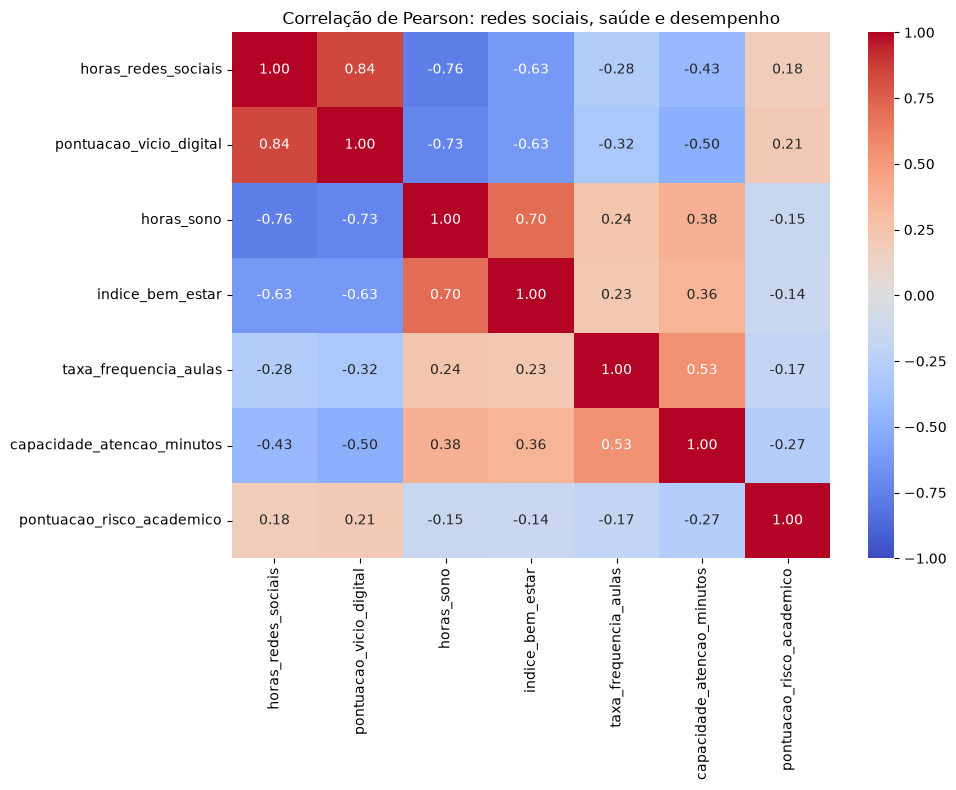

In [3]:
matriz = pd.DataFrame(df.corr().to_numpy(), index=todas, columns=todas)

plt.figure(figsize=(10, 8))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação de Pearson: redes sociais, saúde e desempenho")
plt.tight_layout()
plt.show()

> 🔎 **Interpretação.**
> - **Redes × vício digital (0,84):** a correlação mais alta da matriz. É esperada, pois a pontuação de vício provavelmente é construída a partir do uso, então não deve ser lida como um achado independente.
> - **Sono × bem-estar (0,70):** quem dorme mais tem bem-estar mais alto. Os dois indicadores de saúde andam juntos.
> - **Frequência × atenção (0,53):** estudantes com maior atenção tendem a faltar menos.
> - **Risco acadêmico** tem as correlações mais fracas da matriz (|r| de no máximo 0,27); a maior é com a atenção (-0,27).
> - Redes e vício digital têm **sinais iguais** em todas as relações: negativos com sono, bem-estar, atenção e frequência, e positivos com o risco acadêmico.

### 4.2 Preditores × saúde e desempenho
Pearson e Spearman para cada par entre os dois preditores e os cinco resultados, ordenados pela força da correlação.

In [4]:
def forca(r):
    a = abs(r)
    return "desprezível" if a < 0.1 else "fraca" if a < 0.3 else "moderada" if a < 0.5 else "forte"

linhas = []
for p in preditores:
    for a in alvos:
        if p == a:
            continue
        r = df.select(
            pl.corr(p, a, method="pearson").alias("pearson"),
            pl.corr(p, a, method="spearman").alias("spearman"),
        ).row(0)
        linhas.append({"preditor": p, "alvo": a, "pearson": r[0], "spearman": r[1],
                       "r2": r[0] ** 2, "forca": forca(r[0]),
                       "direcao": "positiva" if r[0] > 0 else "negativa"})

tabela = pl.DataFrame(linhas).with_columns(pl.col("pearson").abs().alias("abs_r")).sort("abs_r", descending=True)
pl.Config.set_tbl_rows(50)
display(tabela.drop("abs_r"))

preditor,alvo,pearson,spearman,r2,forca,direcao
str,str,f64,f64,f64,str,str
"""horas_redes_sociais""","""horas_sono""",-0.761701,-0.750171,0.580188,"""forte""","""negativa"""
"""pontuacao_vicio_digital""","""horas_sono""",-0.727712,-0.714552,0.529565,"""forte""","""negativa"""
"""horas_redes_sociais""","""indice_bem_estar""",-0.632777,-0.621379,0.400407,"""forte""","""negativa"""
"""pontuacao_vicio_digital""","""indice_bem_estar""",-0.629839,-0.617796,0.396697,"""forte""","""negativa"""
"""pontuacao_vicio_digital""","""capacidade_atencao_minutos""",-0.504901,-0.493309,0.254925,"""forte""","""negativa"""
"""horas_redes_sociais""","""capacidade_atencao_minutos""",-0.433372,-0.422437,0.187811,"""moderada""","""negativa"""
"""pontuacao_vicio_digital""","""taxa_frequencia_aulas""",-0.320366,-0.310398,0.102635,"""moderada""","""negativa"""
"""horas_redes_sociais""","""taxa_frequencia_aulas""",-0.276624,-0.267601,0.076521,"""fraca""","""negativa"""
"""pontuacao_vicio_digital""","""pontuacao_risco_academico""",0.2121,0.222239,0.044986,"""fraca""","""positiva"""


**Resumo para as horas em redes sociais**

| Resultado | Pearson | Spearman | r² | Classificação |
|---|---|---|---|---|
| Horas de sono | -0,762 | -0,750 | 0,580 | Forte, negativa |
| Bem-estar | -0,633 | -0,621 | 0,400 | Forte, negativa |
| Capacidade de atenção | -0,433 | -0,422 | 0,188 | Moderada, negativa |
| Frequência às aulas | -0,277 | -0,268 | 0,077 | Fraca, negativa |
| Risco acadêmico | +0,178 | +0,195 | 0,032 | Fraca, positiva |

> 🔎 **Interpretação.**
> - **Gradiente claro:** a força da associação diminui da **saúde** (sono e bem-estar) para o **desempenho** (atenção, frequência e risco acadêmico).
> - **Sono:** as horas em redes explicam cerca de **58%** da variação do sono. É a relação mais forte do estudo.
> - **Bem-estar:** explicam cerca de **40%**.
> - **Risco acadêmico:** explicam apenas cerca de **3%**, ou seja, o desempenho depende de muitos outros fatores.
> - **Pearson e Spearman** diferem em no máximo cerca de 0,02 em todos os pares, o que mostra que os resultados **não dependem de valores extremos**.
> - O **vício digital** segue o mesmo padrão das horas em redes, com correlações de tamanho parecido (por exemplo, -0,73 com o sono e -0,50 com a atenção).

**Mapa de calor dos preditores:**

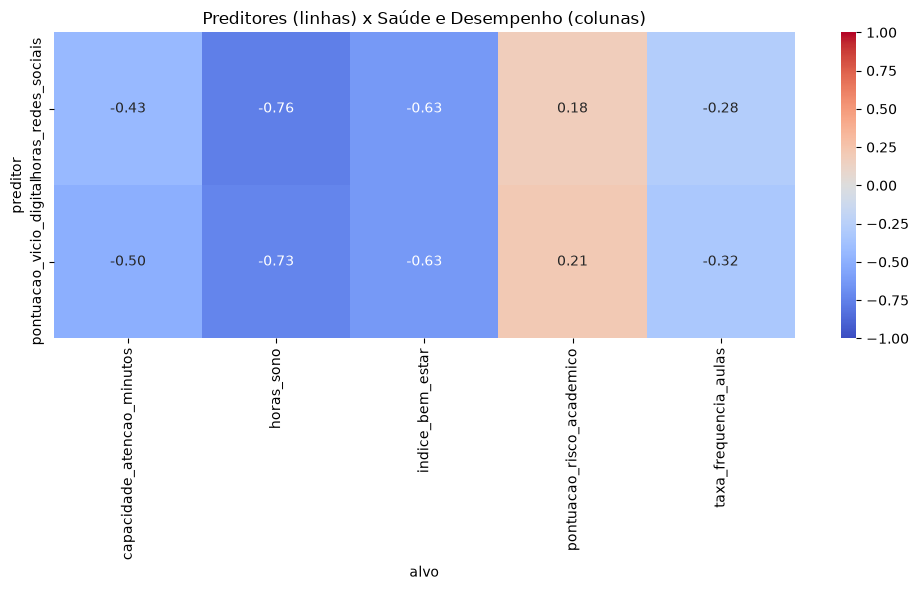

In [5]:
pivot = tabela.to_pandas().pivot(index="preditor", columns="alvo", values="pearson")

plt.figure(figsize=(10, 4 + len(preditores)))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Preditores (linhas) x Saúde e Desempenho (colunas)")
plt.tight_layout()
plt.show()

> 🔎 **Interpretação.** O mapa reúne os resultados da tabela: a faixa azul-escura (sono e bem-estar) mostra onde está a maior associação, enquanto as colunas de frequência e risco acadêmico aparecem em tons mais claros.

### 4.3 Dispersão dos pares mais fortes
Amostra aleatória de 5.000 estudantes (500 mil pontos ficariam ilegíveis), com reta de tendência.

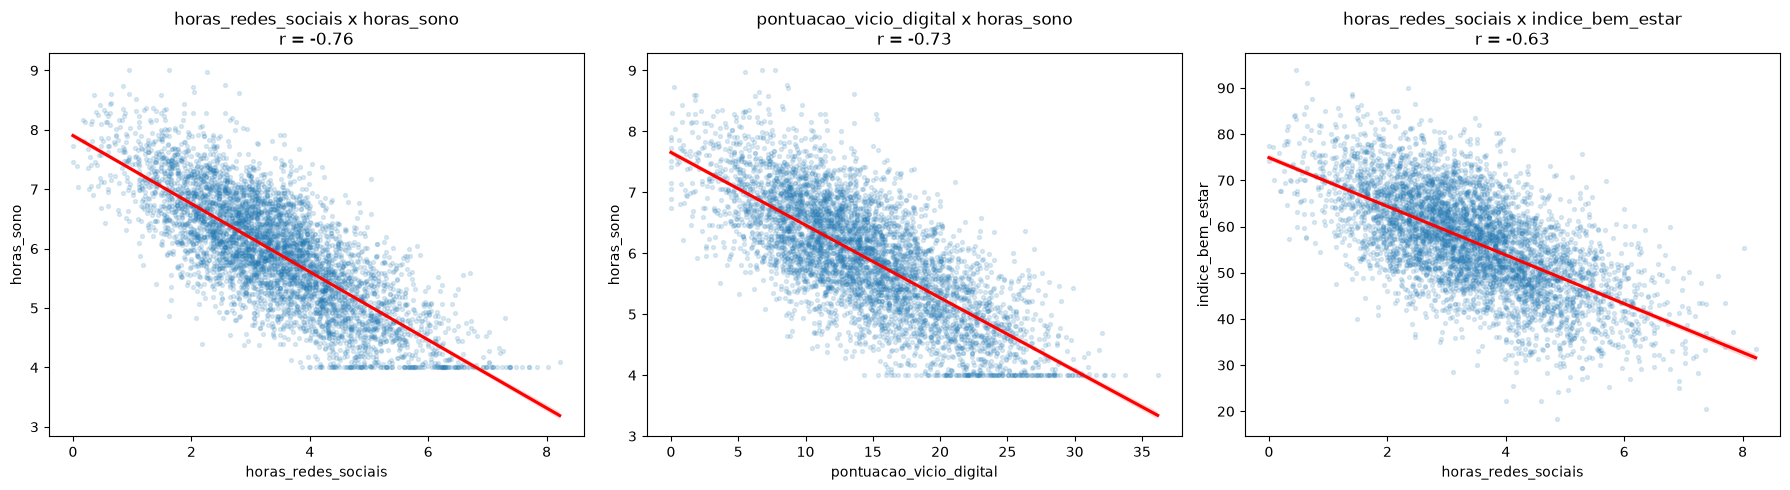

In [6]:
amostra = df.sample(n=min(5000, df.height), seed=42).to_pandas()
top = tabela.head(3).select(["preditor", "alvo", "pearson"]).rows()

fig, axes = plt.subplots(1, len(top), figsize=(6 * len(top), 5), squeeze=False)
for ax, (p, a, r) in zip(axes[0], top):
    sns.regplot(data=amostra, x=p, y=a, ax=ax,
                scatter_kws={"alpha": 0.15, "s": 8}, line_kws={"color": "red"})
    ax.set_title(f"{p} x {a}\nr = {r:.2f}")
plt.tight_layout()
plt.show()

> 🔎 **Interpretação.**
> - Os três gráficos mostram uma **tendência linear descendente**, coerente com os coeficientes.
> - Pela reta de tendência, cada hora adicional em redes sociais se associa a cerca de **0,6 h a menos de sono** e a cerca de **5 pontos a menos de bem-estar** (leitura aproximada do gráfico).
> - **Piso de 4 h de sono:** há um acúmulo de pontos em 4,0 h, o que indica que a variável tem um limite mínimo. Nessa faixa, a reta linear tende a exagerar a queda do sono.

### 4.4 Médias por nível de uso de redes
Visão mais intuitiva: o que acontece com saúde e desempenho conforme o uso de redes aumenta, usando as faixas da Parte 1.

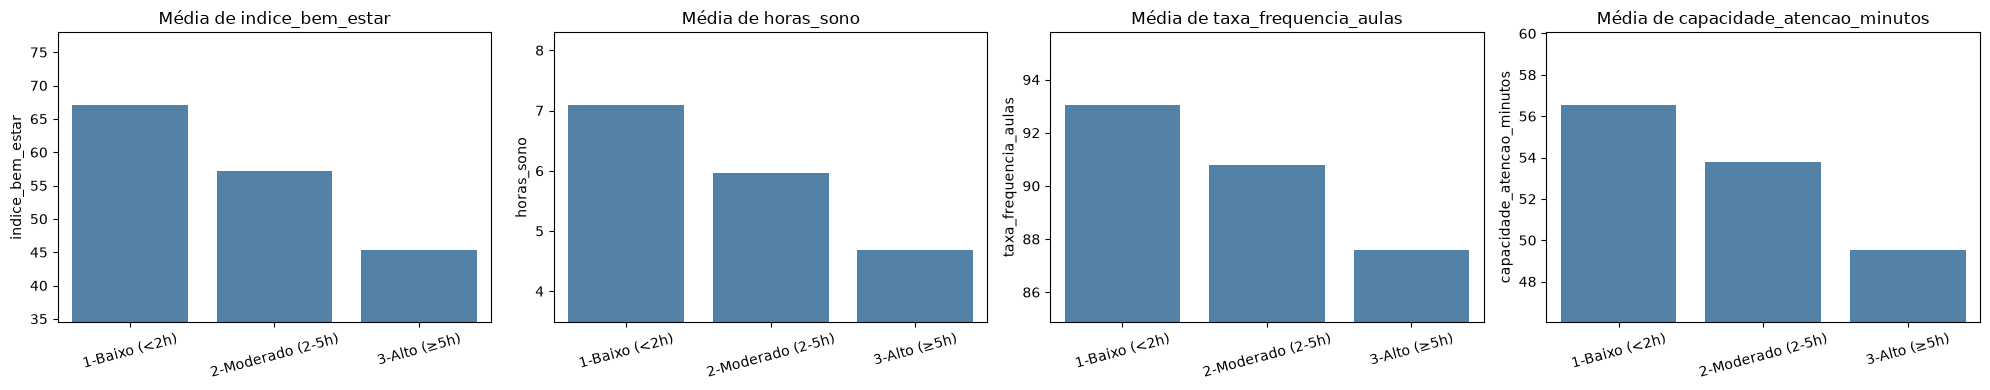

In [7]:
lf_cat = categorizar(inicial)
grupos = ["categoria_redes"]
resumo_alvos = [c for c in ["indice_bem_estar", "horas_sono", "taxa_frequencia_aulas", "capacidade_atencao_minutos"] if c in colunas]

fig, axes = plt.subplots(len(grupos), len(resumo_alvos), figsize=(5 * len(resumo_alvos), 4 * len(grupos)), squeeze=False)
for i, g in enumerate(grupos):
    medias = (
        lf_cat.group_by(g)
        .agg([pl.col(c).mean().alias(c) for c in resumo_alvos])
        .sort(g).collect().to_pandas()
    )
    for j, a in enumerate(resumo_alvos):
        sns.barplot(data=medias, x=g, y=a, ax=axes[i][j], color="steelblue")
        axes[i][j].set_title(f"Média de {a}")
        axes[i][j].set_xlabel("")
        axes[i][j].tick_params(axis="x", rotation=15)
        lo, hi = medias[a].min(), medias[a].max()
        margem = (hi - lo) * 0.5 or 1
        axes[i][j].set_ylim(lo - margem, hi + margem)   # eixo ampliado para mostrar a diferença
plt.tight_layout()
plt.show()

> 🔎 **Interpretação.** Valores aproximados lidos dos gráficos, de *Baixo* para *Alto*:
>
> | Indicador | Baixo (< 2 h) | Moderado (2–5 h) | Alto (≥ 5 h) |
> |---|---|---|---|
> | Bem-estar | ~67 | ~57 | ~45 |
> | Horas de sono | ~7,1 | ~6,0 | ~4,7 |
> | Frequência às aulas | ~93% | ~91% | ~88% |
> | Atenção (min) | ~56,5 | ~54 | ~49,5 |
>
> - Todos os indicadores **pioram a cada nível** de uso, e a queda é maior de *Moderado* para *Alto*.
> - O bem-estar e o sono sofrem as maiores quedas, em linha com as correlações fortes.
> - ⚠️ **Atenção à leitura visual:** o eixo vertical dos gráficos não começa em zero (foi ampliado para destacar as diferenças). Na frequência às aulas, por exemplo, a diferença entre *Baixo* e *Alto* é de cerca de 5 pontos percentuais, menor do que a altura das barras sugere.

### 4.5 Síntese das associações
Resumo gerado automaticamente a partir dos coeficientes.

In [8]:
print("Principais associações (ordenadas por |r|):\n")
for p, a, r, s, f, d in tabela.select(["preditor", "alvo", "pearson", "spearman", "forca", "direcao"]).head(8).rows():
    print(f"- {p} x {a}: Pearson {r:+.3f} | Spearman {s:+.3f} -> correlação {f} {d}")

print("\nSem associação relevante (|r| < 0,10):")
fracas = tabela.filter(pl.col("abs_r") < 0.1).select(["preditor", "alvo"]).rows()
print(", ".join(f"{p} x {a}" for p, a in fracas) or "nenhuma")

Principais associações (ordenadas por |r|):

- horas_redes_sociais x horas_sono: Pearson -0.762 | Spearman -0.750 -> correlação forte negativa
- pontuacao_vicio_digital x horas_sono: Pearson -0.728 | Spearman -0.715 -> correlação forte negativa
- horas_redes_sociais x indice_bem_estar: Pearson -0.633 | Spearman -0.621 -> correlação forte negativa
- pontuacao_vicio_digital x indice_bem_estar: Pearson -0.630 | Spearman -0.618 -> correlação forte negativa
- pontuacao_vicio_digital x capacidade_atencao_minutos: Pearson -0.505 | Spearman -0.493 -> correlação forte negativa
- horas_redes_sociais x capacidade_atencao_minutos: Pearson -0.433 | Spearman -0.422 -> correlação moderada negativa
- pontuacao_vicio_digital x taxa_frequencia_aulas: Pearson -0.320 | Spearman -0.310 -> correlação moderada negativa
- horas_redes_sociais x taxa_frequencia_aulas: Pearson -0.277 | Spearman -0.268 -> correlação fraca negativa

Sem associação relevante (|r| < 0,10):
nenhuma


> 🔎 **Interpretação.** Nenhum par ficou abaixo de 0,10, ou seja, **todas as relações analisadas são, no mínimo, fracas**. Os seis maiores coeficientes estão ligados a sono, bem-estar e atenção.

---
## 5. Discussão

**Como interpretar os coeficientes**

- **Tamanho, não significância:** com 500 mil registros, até correlações muito pequenas são estatisticamente significativas. O que importa é o **tamanho** de r e de r².
- **Vício digital:** a pontuação provavelmente deriva do uso de redes, então sua correlação alta com as horas em redes (0,84) é esperada.
- **Correlação não é causa:** sono, escolaridade e país podem influenciar todas as variáveis ao mesmo tempo.

**O que os resultados sugerem**

- **Sono e redes andam juntos:** com r de -0,76, é difícil separar o efeito de cada um apenas com correlações simples. Isso já aparecia na Parte 1, em que quase todos os usuários intensos dormiam pouco.
- **Hipótese a testar:** o sono pode ser parte do caminho pelo qual as redes afetam o bem-estar e a atenção. O gradiente observado (forte na saúde, fraco no desempenho) é compatível com essa ideia, mas as correlações sozinhas **não a comprovam**.
- **Desempenho:** a frequência e o risco acadêmico têm associação fraca com o uso de redes, o que indica que outros fatores pesam mais para o rendimento.

---
## 6. Conclusões e limitações

**Conclusões**

1. O uso de redes sociais tem **associação forte e negativa** com o sono (r = -0,76) e com o bem-estar (r = -0,63).
2. A associação com a **atenção** é moderada (r = -0,43), e com a **frequência** e o **risco acadêmico** é fraca (|r| abaixo de 0,3).
3. As **médias por faixa** confirmam o padrão da Parte 1: quanto maior o uso, piores os indicadores de saúde e de desempenho.
4. **Pearson e Spearman concordam**, o que dá robustez aos resultados.

In [9]:
import os
import pandas as pd
import polars as pl

PASTA = "csv_powerbi"
os.makedirs(PASTA, exist_ok=True)

def exportar(tabela, nome):
    """Salva uma tabela em CSV pronto para o Power BI."""
    if isinstance(tabela, pl.LazyFrame):
        tabela = tabela.collect()
    if isinstance(tabela, pl.DataFrame):
        tabela = tabela.to_pandas()
    tabela.to_csv(f"{PASTA}/{nome}.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
    print(f"{nome}.csv salvo: {len(tabela):,} linhas")

In [10]:
exportar(perfil(inicial, "nivel_desenvolvimento"), "02_perfil_nivel_desenvolvimento")
exportar(perfil(inicial, "pais"), "03_perfil_por_pais")
exportar(tabela.drop("abs_r"), "09_correlacao_preditores_alvos")
exportar(medias.round(2), "10_medias_por_faixa_redes")

sp = df.to_pandas().corr(method="spearman")
longa = (matriz.round(4).rename_axis("variavel_x").reset_index()
         .melt(id_vars="variavel_x", var_name="variavel_y", value_name="pearson"))
longa["spearman"] = sp.round(4).to_numpy().ravel(order="F")
exportar(longa, "08_matriz_correlacao")

02_perfil_nivel_desenvolvimento.csv salvo: 3 linhas
03_perfil_por_pais.csv salvo: 50 linhas
09_correlacao_preditores_alvos.csv salvo: 10 linhas
10_medias_por_faixa_redes.csv salvo: 3 linhas
08_matriz_correlacao.csv salvo: 49 linhas
